# JavaScript 基础第二天

运算符、语句、循环与简易 ATM

## 课程说明

本日的目标是让程序具备三种能力：用运算符处理数据，用分支语句作出选择，用循环重复执行代码。最后把这些知识组合成一个简易 ATM 存取款机。

本篇依据[百度网盘课程资料](https://pan.baidu.com/s/1MxueOHXGQtmE-ypRq1kELA?pwd=9987)中的「JavaScript基础第二天」整理，提取码 `9987`。来源包括 74 页讲义、原始 Markdown 笔记、XMind、20 份课堂代码以及作业题目和答案。正文遵循原课顺序；算术运算作为配套笔记中的复习内容保留。

标为“课堂原代码”的内容摘录原 HTML 中的 `<script>`，保留变量名、提示文字与注释状态；其余示例是按讲义或题目整理的写法。将 JavaScript 示例放入 HTML 的 `<script>` 标签后用浏览器查看效果；代码以 Markdown 展示，不在 Python 内核中执行。图片直接嵌入 Notebook。原资料的笔误、示例差异和补充说明在对应位置标明。

本日主线：

1. 运算符：算术、赋值、一元、自增自减、比较、逻辑和优先级。
2. 语句：表达式与语句、三大流程结构、`if`、三元、`switch` 和断点调试。
3. 循环：`while`、循环三要素、`break`、`continue` 与无限循环。
4. 综合案例：余额为 100 元的简易 ATM。

## 1. 运算符

### 1.1 算术运算符

算术运算符用于数字计算：

| 运算符 | 作用 |
| --- | --- |
| `+` | 求和 |
| `-` | 求差 |
| `*` | 求积 |
| `/` | 求商 |
| `%` | 取余数（取模） |

`%` 常用来判断整除：对于整数，`num % 2 === 0` 表示 `num` 是偶数。无法得到有效数值时，运算可能返回 `NaN`（Not a Number）。加号遇到字符串时会进行字符串拼接，而减法、乘法和除法会尝试把字符串转换成数字：

```javascript
console.log(1 + 2 * 3 / 2)  // 4
let num = 10
console.log(num + 10)       // 20
console.log(4 % 2)          // 0
console.log(5 % 3)          // 2
console.log('pink老师' - 2)  // NaN
console.log('pink老师' + 2)  // pink老师2
```

算术内容来自原配套 Markdown；第一天已经学过。本日使用取余、赋值和比较运算组合条件。

### 1.2 赋值运算符

`=` 把右侧的值赋给左侧变量，左侧必须是可以保存数据的容器。复合赋值运算符把计算和赋值合在一起：

| 运算符 | 等价写法 | 作用 |
| --- | --- | --- |
| `+=` | `num = num + x` | 加法赋值 |
| `-=` | `num = num - x` | 减法赋值 |
| `*=` | `num = num * x` | 乘法赋值 |
| `/=` | `num = num / x` | 除法赋值 |
| `%=` | `num = num % x` | 取余赋值 |

**资料修正：**原 Markdown 把减法赋值写成 `-+`；讲义第 5 页和正确语法都是 `-=`。

例如：

```javascript
let num = 1
num += 3
console.log(num)  // 4
```

课堂原代码：

课堂原代码（`04-code/01-赋值运算符.html`）：

```javascript
    let num = 1
    // num = num + 1
    // 采取赋值运算符
    // num += 1
    num += 3
    console.log(num)
  
```

### 1.3 一元运算符、自增和自减

只需要一个操作数的运算符叫一元运算符，正负号、`++` 和 `--` 都属于这一类。`++` 让变量加 1，`--` 让变量减 1，常用于循环计数。

| 写法 | 作用 |
| --- | --- |
| `++i` | 先加 1，再使用新值 |
| `i++` | 先使用旧值，再加 1 |
| `--i` | 先减 1，再使用新值 |
| `i--` | 先使用旧值，再减 1 |

前置和后置在单独使用时最终结果相同，实际开发中通常单独使用，后置 `i++` 更常见。自增、自减必须作用于可修改的目标，本课使用 `let` 声明的变量，不能写 `1++`，也不能给 `const` 数值变量自增。

```javascript
let i = 1
console.log(++i)  // 2：先加后用

let j = 1
console.log(j++)  // 1：先用后加
console.log(j)    // 2
```

课堂中的组合表达式用于观察求值顺序：

课堂原代码（`04-code/02-一元运算符.html`）：

```javascript
    // let num = 10
    // num = num + 1
    // num += 1
    // // 1. 前置自增
    // let i = 1
    // ++i
    // console.log(i)

    // let i = 1
    // console.log(++i + 1)
    // 2. 后置自增
    // let i = 1
    // i++
    // console.log(i)
    // let i = 1
    // console.log(i++ + 1)

    // 了解 
    let i = 1
    console.log(i++ + ++i + i)
  
```

原文件当前启用的是 `i++ + ++i + i`。`i` 起初为 `1`：第一项取 `1` 后变 `2`，第二项先变 `3` 再取 `3`，最后一项仍为 `3`，所以输出 `7`，最终 `i` 为 `3`。

不要在一个复杂表达式里混用多个自增自减来写业务逻辑；拆成多条语句更容易阅读和调试。

### 1.4 比较运算符

比较运算的结果是布尔值 `true` 或 `false`：

| 运算符 | 含义 |
| --- | --- |
| `>`、`<` | 大于、小于 |
| `>=`、`<=` | 大于等于、小于等于 |
| `==` | 值相等，允许隐式类型转换 |
| `===` | 值和类型都相等（全等，推荐） |
| `!=` | 值不相等，允许隐式转换 |
| `!==` | 值或类型至少有一个不相等 |

```javascript
console.log(3 > 5)       // false
console.log(3 >= 3)      // true
console.log(2 == '2')    // true，发生隐式转换
console.log(2 === '2')   // false，类型不同
console.log(2 !== '2')   // true
console.log(NaN === NaN) // false，NaN 不等于任何值，包括自己
```

字符串从左到右逐字符按编码比较：`'a' < 'b'` 和 `'aa' < 'ab'` 为 `true`；当前者是后者的完整前缀时，较短者更小，如 `'aa' < 'aac'`。两个字符串不会按数字大小比较，例如 `'10' < '2'` 为 `true`。涉及相等判断时优先使用 `===` 和 `!==`，这样不会把不同类型的数据意外当成相等。

**补充：**讲义把字符编码统称为 ASCII，这可用于理解英文示例，JavaScript 实际按 UTF-16 编码单元比较。讲义“涉及 NaN 都是 false”应理解为相等或大小比较：`NaN === NaN` 为 `false`，而 `NaN !== NaN` 为 `true`。小数还存在精度问题，例如 `0.1 + 0.2 === 0.3` 为 `false`，不能把它当成精确的十进制计算。

课堂原代码（`04-code/03-比较运算符.html`）：

```javascript
    console.log(3 > 5)
    console.log(3 >= 3)
    console.log(2 == 2)
    // 比较运算符有隐式转换 把'2' 转换为 2  双等号 只判断值
    console.log(2 == '2')  // true
    // console.log(undefined === null)
    // === 全等 判断 值 和 数据类型都一样才行
    // 以后判断是否相等 请用 ===  
    console.log(2 === '2')
    console.log(NaN === NaN) // NaN 不等于任何人，包括他自己
    console.log(2 !== '2')  // true  
    console.log(2 != '2') // false 
    console.log('-------------------------')
    console.log('a' < 'b') // true
    console.log('aa' < 'ab') // true
    console.log('aa' < 'aac') // true
    console.log('-------------------------')
  
```

**不要写区间链式比较：** JavaScript 不支持 `5 < num < 10` 这种数学写法。应拆成两个比较并用逻辑与连接：

```javascript
num > 5 && num < 10
```

### 1.5 逻辑运算符

逻辑运算符把多个条件组合起来：

| 符号 | 名称 | 规则 |
| --- | --- | --- |
| `&&` | 逻辑与 | 一假则假；两边都真才为真 |
| `\|\|` | 逻辑或 | 一真则真；两边都假才为假 |
| `!` | 逻辑非 | 真变假，假变真 |

```javascript
console.log(3 < 5 && 3 > 2)  // true
console.log(3 < 5 && 3 < 2)  // false
console.log(false || true)   // true
console.log(!true)           // false

let num = 6
console.log(num > 5 && num < 10)  // true
```

在条件表达式中，逻辑优先级为 `! > && > ||`。条件复杂时主动加括号，可以把意图写清楚。

课堂原代码（`04-code/04-逻辑运算符.html`）：

```javascript
    // 逻辑与 一假则假
    console.log(true && true)
    console.log(false && true)
    console.log(3 < 5 && 3 > 2)
    console.log(3 < 5 && 3 < 2)
    console.log('-----------------')
    // 逻辑或 一真则真
    console.log(true || true)
    console.log(false || true)
    console.log(false || false)
    console.log('-----------------')
    // 逻辑非  取反
    console.log(!true)
    console.log(!false)

    console.log('-----------------')

    let num = 6
    console.log(num > 5 && num < 10)
    console.log('-----------------')
  
```

对于本日布尔条件，可用以下真值表理解：

| A | B | A && B | A \|\| B | !A |
| --- | --- | --- | --- | --- |
| false | false | false | false | true |
| false | true | false | true | true |
| true | false | false | true | false |
| true | true | true | true | false |

**补充：**`&&`、`||` 作用于非布尔数据时会返回其中一个操作数，本日先用它们连接比较条件；`!` 的结果始终是布尔值。

讲义第 27 页练习：用户输入一个数，判断它是否为 4 的倍数，并且不是 100 的倍数。输入 `8` 输出 `true`，输入 `100` 输出 `false`。

课堂原代码（`04-code/05-用户输入案例.html`）：

```javascript
    // 1. 用户输入
    let num = +prompt('请输入一个数字:')
    // 2. 弹出结果
    alert(num % 4 === 0 && num % 100 !== 0)
  
```

这只是两个条件的组合练习；完整闰年判断还要考虑“能被 400 整除”的情况，后文会补上。

### 1.6 运算符优先级

常用优先级从高到低大致为：小括号 `()`、一元运算符（如 `!`、`++`）、算术运算符、比较运算符、逻辑与 `&&`、逻辑或 `||`、赋值运算符。实际代码中，遇到不确定的组合就加括号，避免依赖记忆。

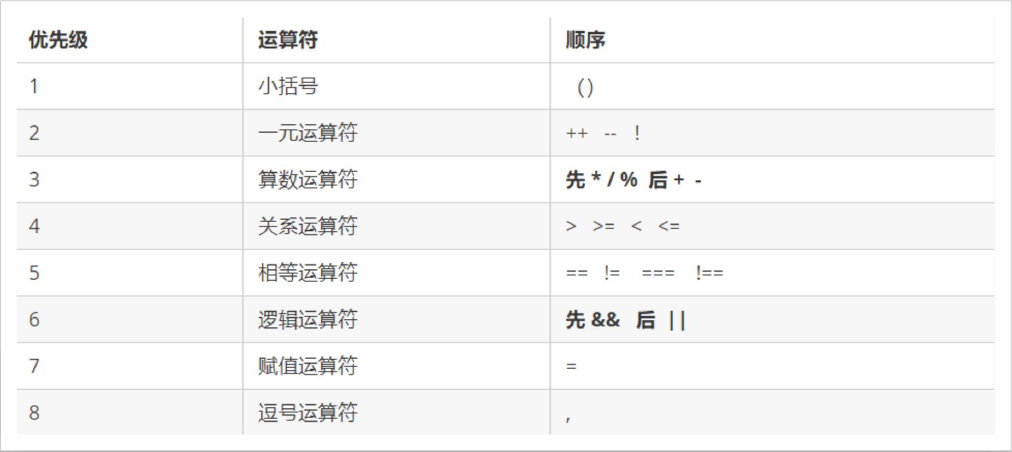

讲义第 30 页练习，先自己判断输出结果：

```javascript
let a = 3 > 5 && 2 < 7 && 3 == 4
console.log(a)
let b = 3 <= 4 || 3 > 1 || 3 != 2
console.log(b)
let c = 2 === '2'
console.log(c)
let d = !c || b && a
console.log(d)
```

依次为 `false`、`true`、`false`、`true`。最后一项相当于 `(!c) || (b && a)`，先取反，再做与，最后做或。

## 2. 语句与流程控制

### 2.1 表达式和语句

表达式是可以被求值的代码片段，例如 `3 + 5`、`num > 5`。语句是完成某种操作的完整指令，例如变量声明、赋值、条件判断和循环。一个语句可以包含表达式：`let sum = 3 + 5`。

**补充：**讲义把 `alert()` 列为不能用于赋值的语句，这是教学简化。调用本身是表达式，`let result = alert('你好')` 在语法上成立，但返回 `undefined`。`if`、`while`、`break` 等语句不能直接放到赋值号右侧。

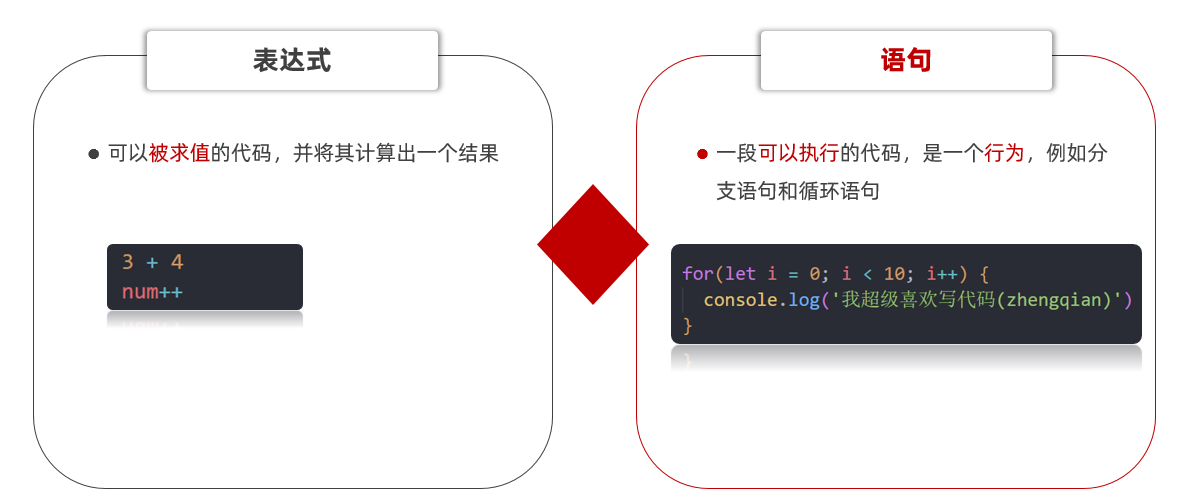

程序通常有三种基本流程结构：

1. **顺序结构**：代码从上到下依次执行。
2. **分支结构**：根据条件选择要执行的路径。
3. **循环结构**：满足条件时重复执行一段代码。

### 2.2 `if` 分支语句

#### 单分支：满足条件才执行

单分支只在条件为真时执行：

```javascript
if (条件表达式) {
  // 条件为 true 时执行
}
```

条件不是布尔值时会发生布尔转换：`0`、空字符串 `''`、`undefined`、`null` 和 `NaN` 会转为 `false`，其他常见值转为 `true`。即使只有一条语句也建议保留大括号，避免后续修改时产生歧义。

```javascript
let score = +prompt('请输入成绩')
if (score >= 700) {
  alert('恭喜考入黑马程序员')
}
```

课堂原代码（`04-code/06-if单分支语句.html`）：

```javascript
    // 单分支语句
    // if (false) {
    //   console.log('执行语句')
    // }
    // if (3 > 5) {
    //   console.log('执行语句')
    // }
    // if (2 === '2') {
    //   console.log('执行语句')
    // }
    //  1. 除了0 所有的数字都为真
    //   if (0) {
    //     console.log('执行语句')
    //   }
    // 2.除了 '' 所有的字符串都为真 true
    // if ('pink老师') {
    //   console.log('执行语句')
    // }
    // if ('') {
    //   console.log('执行语句')
    // }
    // // if ('') console.log('执行语句')

    // 1. 用户输入
    let score = +prompt('请输入成绩')
    // 2. 进行判断输出
    if (score >= 700) {
      alert('恭喜考入黑马程序员')
    }
    console.log('-----------------')

  
```

当前启用的代码输入 `700` 会弹窗，输入 `699` 不会弹窗；两种情况都会执行后面的控制台输出。原注释“除了 0 所有数字都为真”忽略了 `NaN`，上面的转换说明已补齐。

#### 双分支：二选一

双分支在两条路径中选择一条：

```javascript
if (条件表达式) {
  // 满足条件
} else {
  // 不满足条件
}
```

例如登录校验：

课堂原代码（`04-code/07-双分支语句.html`）：

```javascript
    // 1. 用户输入
    let uname = prompt('请输入用户名:')
    let pwd = prompt('请输入密码:')
    // 2. 判断输出
    if (uname === 'pink' && pwd === '123456') {
      alert('恭喜登录成功')
    } else {
      alert('用户名或者密码错误')
    }
  
```

输入用户名 `pink`、密码 `123456` 才成功；密码保留字符串，因为此处是匹配而非计算。

#### 双分支练习：判断闰年

闰年条件是：能被 4 整除且不能被 100 整除，或者能被 400 整除。写清分组可记为 `(year % 4 === 0 && year % 100 !== 0) || year % 400 === 0`。

课堂原代码（`04-code/08-闰年案例.html`）：

```javascript
    // 1. 用户输入
    let year = +prompt('请输入年份')
    // 2. 判断输出
    if (year % 4 === 0 && year % 100 !== 0 || year % 400 === 0) {
      alert(`${year}年是闰年`)
    } else {
      alert(`${year}年是平年`)
    }
  
```

测试：`2024` 和 `2000` 为闰年，`1900` 和 `2023` 为平年。

#### 多分支：依次判断

多分支使用 `else if` 按顺序判断，命中第一条条件后就结束：

```javascript
let score = +prompt('请输入成绩：')
if (score >= 90) {
  alert('成绩优秀')
} else if (score >= 70) {
  alert('成绩良好')
} else if (score >= 60) {
  alert('成绩及格')
} else {
  alert('成绩不及格')
}
```

区间判断要按从高到低或从低到高排列。这里先判断 `>= 90`，所以进入 `>= 70` 分支的数据已经满足 `< 90`，无需重复写上界。

课堂原代码（`04-code/09-判断成绩案例.html`）：

```javascript
    // 1. 用户输入
    let score = +prompt('请输入成绩：')
    // 2. 判断输出
    if (score >= 90) {
      alert('成绩优秀，宝贝，你是我的骄傲')
    } else if (score >= 70) {
      alert('成绩良好，宝贝，你要加油哦~~')
    } else if (score >= 60) {
      alert('成绩及格，宝贝，你很危险~')
    } else {
      alert('成绩不及格，宝贝，我不想和你说话，我只想用鞭子和你说话~')
    }
  
```

本课堂代码的边界是：`>= 90` 优秀，`70~89` 良好，`60~69` 及格，`< 60` 不及格。输入 `90`、`70`、`60`、`59` 可检查四条路径。默认输入有效成绩；更完整的程序还需要处理超出范围和 `NaN`。

### 2.3 三元运算符

三元表达式是简单双分支的简写，并且会产生一个结果值：

```javascript
条件 ? 表达式1 : 表达式2
```

条件为真取表达式 1，否则取表达式 2。例如求最大值：

```javascript
let num1 = +prompt('请您输入第一个数：')
let num2 = +prompt('请您输入第二个数：')
let max = num1 > num2 ? num1 : num2
alert(`最大值是：${max}`)
```

补零案例利用三元表达式把一位数字前面补上字符 `0`：

课堂原代码（`04-code/10-三元运算符.html`）：

```javascript
    // 三元运算符
    // 条件 ? 代码1 : 代码2
    // console.log(3 > 5 ? 3 : 5)
    // if (3 < 5) {
    //   alert('真的')
    // } else {
    //   alert('假的')
    // }
    // 3 < 5 ? alert('真的')  : alert('假的')

    let sum = 3 < 5 ? 3 : 5
    console.log(sum)
  
```

当前输出 `3`，因为 `3 < 5` 为真，取问号后的第一个值。

课堂原代码（`04-code/11-求最大值案例.html`）：

```javascript
    // 1. 用户输入
    let num1 = +prompt('请您输入第一个数：')
    let num2 = +prompt('请您输入第二个数：')
    // 2. 判断输出-三元运算符
    // if (num1 > num2) {
    //   alert(num1)
    // } else {
    //   alert(num2)
    // }
    num1 > num2 ? alert(`最大值是: ${num1}`) : alert(`最大值是: ${num2}`)
  
```

课堂原代码（`04-code/12-数字补0案例.html`）：

```javascript
    // let age = 18 
    // age = age + 1
    //  age++

    // 1. 用户输入 
    let num = prompt('请您输入一个数字:')
    // 2. 判断输出- 小于10才补0
    // num = num < 10 ? 0 + num : num
    num = num >= 10 ? num : 0 + num
    alert(num)

  
```

补零原码故意没有写 `+prompt()`：输入 `9` 得到字符串 `'9'`，比较 `num >= 10` 时转换成数字，而 `0 + num` 执行字符串拼接，得到 `'09'`。若先把输入转为数字，`0 + 9` 仍是 `9`，不会补零；明确的字符串写法可用 `'0' + num`。本例按有效非负整数练习。

三元表达式适合简单选择；分支多、逻辑长时使用 `if...else` 更清楚。

### 2.4 `switch` 选择语句

`switch` 适合把一个值与多个确定值比较；范围判断仍然使用 `if...else if`。

```javascript
switch (表达式) {
  case 值1:
    // 代码 1
    break
  case 值2:
    // 代码 2
    break
  default:
    // 没有匹配时执行
}
```

匹配使用全等 `===`，所以 `1` 和 `'1'` 不是同一个 case。通常每个 case 都要写 `break`，否则会继续执行下面的 case，这叫 **case 穿透**。

课堂原代码（`04-code/13-switch选择语句.html`）：

```javascript
    switch (2) {
      case 1:
        console.log('您选择的是1')
        break  // 退出switch
      case 2:
        console.log('您选择的是2')
        break  // 退出switch
      case 3:
        console.log('您选择的是3')
        break  // 退出switch
      default:
        console.log('没有符合条件的')
    }
  
```

简单计算器把运算符作为匹配值：

课堂原代码（`04-code/14-简单计算器.html`）：

```javascript
    // 1.用户输入  2个数字 +  操作符号  + - *  / 
    let num1 = +prompt('请您输入第一个数字:')
    let num2 = +prompt('请您输入第二个数字:')
    let sp = prompt('请您输入 + - * / 其中一个:')
    // 2. 判断输出
    switch (sp) {
      case '+':
        alert(`两个数的加法操作是${num1 + num2}`)
        break
      case '-':
        alert(`两个数的减法操作是${num1 - num2}`)
        break
      case '*':
        alert(`两个数的乘法操作是${num1 * num2}`)
        break
      case '/':
        alert(`两个数的除法操作是${num1 / num2}`)
        break
      default:
        alert(`你干啥咧，请输入+-*/`)

    } 
  
```

### 2.5 断点调试

断点用于观察程序执行到某一行时的变量值和执行路径：

1. 在浏览器按 `F12` 打开开发者工具。
2. 进入 **Sources（源代码）** 面板并打开脚本文件。
3. 点击代码行号设置断点，刷新页面或重新操作。
4. 程序暂停后查看变量，使用继续、单步执行等按钮逐行观察。

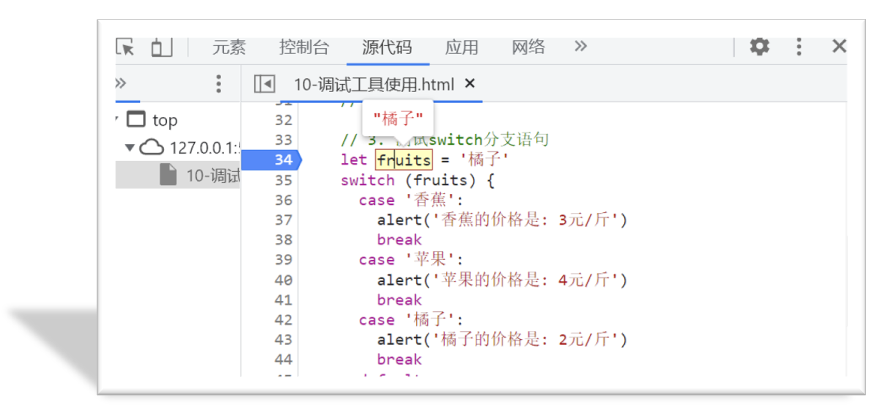

断点通常在目标行执行之前暂停。以 `num = num + 1` 这一行为断点，执行前看到 `num` 为 `10`，单步执行后变为 `11`。课堂演示：

课堂原代码（`04-code/15-断点演示.html`）：

```javascript
    let num = 10
    num = num + 1
    console.log(num)
  
```

## 3. 循环语句

### 3.1 `while` 循环

`while` 在条件为真期间重复执行循环体：

```javascript
while (条件表达式) {
  // 循环体
}
```

循环需要三个要素：

1. **初始值**：循环从哪里开始。
2. **终止条件**：什么时候停止。
3. **变化量**：每次循环让变量靠近终止条件，常用 `i++` 或 `i--`。

缺少终止条件或变化量会造成死循环。示例：输出指定次数的文字。

```javascript
let end = +prompt('请输入次数：')
let i = 1
while (i <= end) {
  document.write(`这是第${i}次循环<br>`)
  i++
}
```

课堂原代码（`04-code/16-while循环.html`）：

```javascript
    // // 1. 变量的起始值
    // let i = 1
    // // 2. 终止条件
    // while (i <= 3) {
    //   document.write('我要循环三次 <br>')
    //   // 3. 变量的变化量
    //   i++
    // }
    // 1. 变量的起始值
    let end = +prompt('请输入次数:')
    let i = 1
    // 2. 终止条件
    while (i <= end) {
      document.write('我要循环三次 <br>')
      // 3. 变量的变化量
      i++
    }

  
```

原课堂代码提示可以输入次数，但输出文字固定写“我要循环三次”，实际次数由 `end` 决定。输入 `3`，`i` 取 `1`、`2`、`3` 时执行；自增到 `4` 后条件为假，退出。若一开始条件为假，循环体一次也不会执行。

### 3.2 循环练习：输出、累加与筛选

循环变量可以同时充当计数器。累加时先准备 `sum = 0`，每次把当前值加进去；筛选偶数时先用 `%` 判断，再进行累加。

下面各组可以单独练习；在同一个脚本中执行时，先声明变量，后面用赋值重置：

```javascript
// 输出 1~100
let i = 1
while (i <= 100) {
  document.write(`${i}<br>`)
  i++
}

// 1~100 的累加和
i = 1
let sum = 0
while (i <= 100) {
  sum += i
  i++
}
console.log(sum)  // 5050

// 1~100 的偶数和
i = 1
sum = 0
while (i <= 100) {
  if (i % 2 === 0) {
    sum += i
  }
  i++
}
console.log(sum)  // 2550
```

课堂练习代码（原文件中保留了前两个练习的注释示例，当前运行的是偶数和）：

课堂原代码（`04-code/17-循环大练习.html`）：

```javascript
    // let age = 18
    // age = age + 1
    // age += 1
    // 1. 页面输出1~100
    // let i = 1
    // while (i <= 100) {
    //   document.write(`这是第${i}个数<br>`)
    //   i++
    // }
    // 2. 页面输出1~100 累加和
    // let i = 1  // 变量的起始值
    // let sum = 0  // 累加和变量
    // while (i <= 100) {
    //   // 把i 累加到 sum 里面
    //   // sum = sum + i
    //   sum += i
    //   i++
    // }
    // console.log(sum) // 5050
    // 3. 页面输出1~100 偶数和
    let i = 1
    let sum = 0
    while (i <= 100) {
      // 筛选偶数 只有偶数才累加
      if (i % 2 === 0) {
        sum = sum + i
      }
      // 每次循环都要自加
      i++
    }
    console.log(sum)
  
```

原文件当前只在控制台输出偶数和 `2550`；讲义要求页面输出时，可改为 `document.write(sum)`。`sum` 必须放在循环外初始化，放在循环内会不断清零；筛选后的 `i++` 必须每次执行，不能只在偶数分支里执行。

### 3.3 `break` 和 `continue`

| 关键字 | 作用 | 适用场景 |
| --- | --- | --- |
| `break` | 退出整个循环 | 已经得到结果，不需要继续查找 |
| `continue` | 结束本次循环，进入下一次 | 跳过某个值或排除某一项 |

```javascript
let i = 1
while (i <= 5) {
  if (i === 3) {
    i++
    continue  // 跳过 3
  }
  console.log(i)
  i++
}
```

使用 `continue` 时要保证循环变量仍然变化，否则会在同一条件上不断重复。

课堂原代码（`04-code/18-continue和break退出循环.html`）：

```javascript
    // let i = 1
    // while (i <= 5) {
    //   console.log(i)
    //   if (i === 3) {
    //     break  // 退出循环
    //   }
    //   i++

    // }


    let i = 1
    while (i <= 5) {
      if (i === 3) {
        i++
        continue
      }
      console.log(i)
      i++

    }
  
```

当前启用的 `continue` 示例输出 `1、2、4、5`；原文件中注释掉的 `break` 示例先输出再判断，到 `3` 就退出，因此输出 `1、2、3`。比较两者时一次只启用一组，避免重复声明 `let i`。

### 3.4 无限循环

`while (true)` 和 `for (;;)` 可以构造有明确退出条件的无限循环。循环体中必须在合适的时候 `break`：

```javascript
while (true) {
  let answer = prompt('你爱我吗？')
  if (answer === '爱') {
    break
  }
}
```

课堂案例：

课堂原代码（`04-code/19-你爱我吗.html`）：

```javascript
    while (true) {
      let str = prompt('你爱我吗')
      // 退出条件 爱
      if (str === '爱') {
        break
      }
    }
  
```

输入“爱”后结束，否则重新询问。点击取消返回 `null`，并不等于“爱”，因此原例仍会再次弹窗。无限循环适合次数不确定但退出条件明确的场景。本日主用 `while`，`for` 的完整语法将在后一天展开。

## 4. 综合案例：简易 ATM

### 4.1 需求与分析

初始余额为 100 元，菜单提供四个操作：`1` 存钱、`2` 取钱、`3` 查看余额、`4` 退出。菜单必须写在循环内部，用户每完成一次操作后重新显示菜单；输入 `4` 时用 `break` 退出循环。

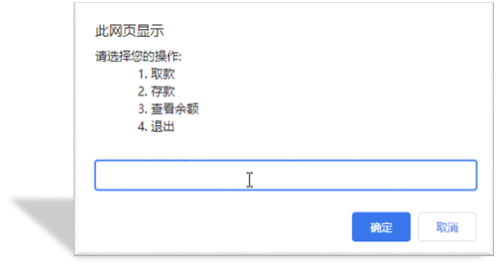

**资料差异：**这张旧示意图把 `1` 写成取款、`2` 写成存款；第二天课堂代码使用 `1` 存钱、`2` 取钱。本篇按照实际课堂代码说明菜单。

实现步骤：

1. 用 `let money = 100` 保存余额。
2. 用 `while (true)` 反复接收操作。
3. `prompt()` 得到字符串，用一元 `+` 转为数字。
4. 先判断退出选项，再用 `switch` 分别处理存钱、取钱和查看余额。
5. 每个 case 处理完后 `break`，避免穿透。

### 4.2 完整课堂代码

课堂原代码（`04-code/20-综合案例-建议ATM取款机.html`）：

```javascript
    // 1. 开始循环 输入框写到 循环里面
    // 3. 准备一个总的金额
    let money = 100
    while (true) {
      let re = +prompt(`
        请您选择操作：
        1.存钱
        2.取钱
        3.查看余额
        4.退出
        `)
      // 2. 如果用户输入的 4 则退出循环， break  写到if 里面，没有写到switch里面， 因为4需要break退出循环
      if (re === 4) {
        break
      }
      // 4. 根据输入做操作
      switch (re) {
        case 1:
          // 存钱
          let cun = +prompt('请输入存款金额')
          money = money + cun
          break
        case 2:
          // 存钱
          let qu = +prompt('请输入取款金额')
          money = money - qu
          break
        case 3:
          // 存钱
          alert(`您的银行卡余额是${money}`)
          break
      }
    }
  
```

`money` 放在 `while` 外面，才能保留多次操作后的余额。放到循环里面，每次显示菜单都会重置成 `100`。

**为什么退出判断放在 `switch` 前面？** `break` 退出最近一层循环或 `switch`。case 内的 `break` 只退出 `switch`，下一轮菜单还会出现；`if (re === 4)` 位于 `switch` 外，里面的 `break` 才退出 `while`。

验证顺序：先选 `3` 显示余额 `100`；选 `1` 存入 `50` 后余额变 `150`；选 `2` 取出 `20` 后余额变 `130`；再次选 `3` 应显示 `130`；输入 `4` 结束，不再弹出菜单。

**补充：**原例 `case 2`、`case 3` 仍写着“存钱”注释，实际分别是取钱和查余额。它没有检验负数、非数字或余额不足，非法选项会重新显示菜单；点击取消也不会退出。练习时可进一步补上金额校验、余额检查和取消处理。

## 5. 当天作业与参考答案

以下按 `05-作业/题目/JavaScript基础第02天作业.md` 的八道核心题、综合变形题和四道排错题整理。先独立完成，再对照。下面的参考示例按题目要求编写，区别于上文保留的课堂原代码。

### 5.1 循环练习

原答案的第 1、2、3、5 题使用 `for`，本日主讲 `while`，这里用已经学过的 `while` 完成相同需求。原题要求页面输出的地方使用 `document.write()`，原答案部分写成控制台输出，在这里按题意修正。

#### 题 1：控制台打印 0~20

```javascript
let i = 0
while (i <= 20) {
  console.log(i)
  i++
}
```

从 `0` 到 `20` 共打印 `21` 个整数，边界包含 `20`。

#### 题 2：页面输出 1~1000 的累加和

```javascript
let i = 1
let sum = 0
while (i <= 1000) {
  sum += i
  i++
}
document.write(`1~1000之间的累加和是：${sum}`)
```

结果为 `500500`。累加变量放在循环外，每次只增加当前 `i`。

#### 题 3：页面输出 100~200 中能被 6 整除的数

```javascript
let i = 100
while (i <= 200) {
  if (i % 6 === 0) {
    document.write(`${i}<br>`)
  }
  i++
}
```

输出从 `102` 开始，到 `198` 结束，每次相差 `6`，共 `17` 个数。

#### 题 5：计算 1 到用户输入值的累加和

```javascript
let n = +prompt('请输入一个数字')
let i = 1
let sum = 0
while (i <= n) {
  sum += i
  i++
}
console.log(`累加和是：${sum}`)
```

按题目预期输入正整数：输入 `5` 得到 `15`，输入 `10` 得到 `55`。以上每题分别放到一个脚本中运行，避免在同一作用域重复声明 `let i`、`let sum`。

### 5.2 题 4：三元表达式求最大值

题目要求：弹窗输入两个数字，在页面输出最大值。课堂例用 `alert()`，作业这里换成页面输出。

```javascript
let num1 = +prompt('请输入第一个数字')
let num2 = +prompt('请输入第二个数字')
let max = num1 > num2 ? num1 : num2
document.write(`最大值是：${max}`)
```

两个数先转换为数字，避免字符串按字符编码比较。输入 `10` 和 `2` 应输出 `10`；两个数相等时取哪一个结果都相同。

### 5.3 题 6：成绩分级

题目边界为 `>= 90` 输出 A，`80~89` 输出 B，`70~79` 输出 C，`60~69` 输出 D，`< 60` 输出 E。与课堂“优良及格不及格”的四档不同，这里要写五档。

```javascript
let score = +prompt('请输入成绩：')
if (score >= 90) {
  console.log('A')
} else if (score >= 80) {
  console.log('B')
} else if (score >= 70) {
  console.log('C')
} else if (score >= 60) {
  console.log('D')
} else {
  console.log('E')
}
```

按有效分数练习；重点检查 `90`、`80`、`70`、`60` 与 `59`。

### 5.4 题 7：星期判断

原题示例是输入“星期一”，在页面输出 `monday`；参考答案却改为输入 `1~7`，在控制台输出中文。这里按原题示例完成，`switch` 接收字符串，case 也保持字符串。

```javascript
let day = prompt('请输入星期一至星期日（星期天也可以）')
switch (day) {
  case '星期一':
    document.write('monday')
    break
  case '星期二':
    document.write('tuesday')
    break
  case '星期三':
    document.write('wednesday')
    break
  case '星期四':
    document.write('thursday')
    break
  case '星期五':
    document.write('friday')
    break
  case '星期六':
    document.write('saturday')
    break
  case '星期日':
  case '星期天':
    document.write('sunday')
    break
  default:
    document.write('请输入正确的星期名称')
}
```

`星期日` 和 `星期天` 共用一段代码，前一个 case 故意不写 `break`，这是有意使用穿透；其他独立分支需要 `break`。

### 5.5 题 8：用户登录验证

用户名为 `admin` 且密码为字符串 `123456` 才成功，否则重新输入两项：

```javascript
// 用户名和密码不正确时一直输入
while (true) {
  let username = prompt('请输入用户名')
  let password = prompt('请输入密码')
  if (username === 'admin' && password === '123456') {
    break
  }
}
alert('登录成功')
```

两个输入都放到循环内部，才能在错误后更新。只有同时满足用户名和密码，`&&` 才为真。原参考也是输入正确才退出，取消输入仍会再次询问。

### 5.6 综合变形：连续计算器

与课堂的一次性计算器不同：先选择操作符，再输入两个数，计算完继续显示菜单，输入 `q` 退出；要求使用 `if` 多分支。

```javascript
// 持续计算，输入 q 退出
while (true) {
  let op = prompt('请输入 + - * / 进行计算，输入 q 退出')
  if (op === 'q') {
    break
  }
  if (op !== '+' && op !== '-' && op !== '*' && op !== '/') {
    alert('请输入 +、-、*、/ 或 q')
    continue
  }

  let x = +prompt('请输入第一个数字')
  let y = +prompt('请输入第二个数字')
  if (op === '+') {
    alert(`两个数的和是：${x + y}`)
  } else if (op === '-') {
    alert(`两个数的差是：${x - y}`)
  } else if (op === '*') {
    alert(`两个数的乘积是：${x * y}`)
  } else {
    alert(`两个数的商是：${x / y}`)
  }
}
```

**资料差异与补充：**原答案写了四个独立 `if`，在操作符互斥时也能得到结果；这里按题目提示改为 `if...else if...else`，并增加非法操作符检查。数字仍按有效输入练习；原需求没有处理除数为 0，JavaScript 的 `1 / 0` 会得到 `Infinity`。

验证：选择 `+`，输入 `2`、`3` 弹出 `5`；返回菜单后选 `*`，输入 `4`、`5` 弹出 `20`；输入 `q` 后不再询问两个数字。

### 5.7 排错题

#### 题 1：求和变成拼接

原代码用 `prompt()` 接收两个值后直接 `alert(num1 + num2)`。`prompt()` 返回字符串，输入 `2` 和 `3` 会得到 `'23'`。求和前转成数字：

```javascript
let num1 = +prompt('请输入第一个值')
let num2 = +prompt('请输入第二个值')
alert(num1 + num2)
```

#### 题 2：把比较写成了赋值

原条件为 `if (username = '迪丽热巴')`。它先把变量改为这个非空字符串，赋值表达式的值再转换为 `true`，所以任何输入都会提示正确。改用 `===`：

```javascript
let username = prompt('请输入用户名:')
if (username === '迪丽热巴') {
  alert('用户名输入正确')
} else {
  alert('用户名输入不正确')
}
```

#### 题 3：循环边界错误且遗漏变化量

原例 `i = 1`，条件写 `while (i < num)`，循环内没有 `i++`。输入大于 `1` 的值会一直重复第 1 句；输入 `1` 则一条也不输出。从 1 打印到用户输入值时应使用 `<=` 并自增：

```javascript
let num = +prompt('请输入一个1~10之间的整数')
let i = 1
while (i <= num) {
  console.log(`我是第${i}句话`)
  i++
}
```

输入 `3`，应输出第 `1`、`2`、`3` 句话。这里另补了数字转换，范围仍按题目预期输入。

#### 题 4：`switch` 类型不匹配和 case 穿透

原例用 `+prompt()` 得到数字，但 case 写成 `'1'`、`'2'` 等字符串，因此匹配失败；另外各 case 缺少 `break`。这里统一为数字，并结束各分支：

```javascript
let num = +prompt('请你输入一个1-4之间的值')
switch (num) {
  case 1:
    alert('春')
    break
  case 2:
    alert('夏')
    break
  case 3:
    alert('秋')
    break
  case 4:
    alert('冬')
    break
  default:
    alert('请输入1~4之间整数')
    break
}
```

输入 `2` 只弹出“夏”；输入 `5` 走 `default`。另一种修法是保留字符串 case，同时去掉 `prompt()` 前的一元 `+`。

### 5.8 关键字速查与复习路线

| 关键字 | 用途 |
| --- | --- |
| `let` | 声明变量 |
| `typeof` | 检测数据类型 |
| `if` / `else` | 条件分支 |
| `switch` / `case` / `default` | 多个确定值的分支 |
| `while` | 条件循环 |
| `break` | 退出循环或 `switch` |
| `continue` | 跳过本次循环 |

课程复习路线：先用 XMind 或 Markdown 梳理本日知识，按顺序独立重写课堂案例，完成当天作业；下一天继续学习 `for` 循环和数组。讲义提供[当天复习测试](https://ks.wjx.top/vj/h46xYbn.aspx)，作业另有[客观题链接](https://ks.wjx.top/vm/tjmrvAg.aspx#)。

检查自己能否说明：`=`、`==`、`===` 的区别；闰年条件如何分组；`if` 为什么只执行一条分支；`switch` 为什么需要 `break`；循环三要素是什么；ATM 中两种 `break` 分别退出哪一层。再修改边界输入，观察类型转换和循环变量变化。